# Univariate analysis

### Import the required packages

In [1]:
system("git clone https://github.com/MarinaAth/metabolomics-course-ebi.git")
setwd("./metabolomics-course-ebi")

In [2]:
install.packages(c('readr', 'ggplot2', 'doParallel', 'scales'))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘foreach’, ‘iterators’




In [3]:
library(readr)
library(ggplot2)
library(doParallel)
library(scales)

registerDoParallel()

Loading required package: foreach

Loading required package: iterators

Loading required package: parallel


Attaching package: ‘scales’


The following object is masked from ‘package:readr’:

    col_factor




### Load the example dataset using the readr package

In [4]:
lcMSDataset <- readr::read_csv('./Data/Dementia_RPOS_XCMS_Dataset.csv')

firstMetaboliteColIdx <- 6

Rows: 168 Columns: 3226
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (3): Sample File Name, Sample ID, Gender
dbl (3223): Run Order, Age, 81.92_70.065m/z, 78.48_76.0391m/z, 234.45_77.038...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


The age-adjusted log fold change (Male vs Female) is extracted directly from the `GenderMale` coefficient of the linear model fitted below. This ensures the fold change is consistent with the p-values, both of which account for Age as a covariate.

## Linear model analysis

Define a function to apply to each metabolite and extract effect size estimates and p-values

In [5]:
fitLMModel <- function(dataset, var) {

  featureName <- colnames(dataset)[var]
  lmModel <- lm(log(get(featureName) + 1) ~ Age + Gender, data=dataset)
  lmModelSummary <- summary(lmModel)
  fStat <- lmModelSummary$fstatistic
  r2AOVpval <- pf(fStat[1],fStat[2],fStat[3],lower.tail=F)

  linearModelResults <- c(Feature=featureName, r2=lmModelSummary$r.squared, Age=lmModelSummary$coefficients['Age', 't value'],
                                Gender=lmModelSummary$coefficients['GenderMale', 't value'],
                                r2_pval=r2AOVpval,
                                age_pval=lmModelSummary$coefficients['Age', 'Pr(>|t|)'],
                                Gender_pval=lmModelSummary$coefficients['GenderMale', 'Pr(>|t|)'],
                                Gender_estimate=lmModelSummary$coefficients['GenderMale', 'Estimate'],
                                Age_estimate=lmModelSummary$coefficients['Age', 'Estimate'])

return(linearModelResults)

}

Apply the linear model analysis function to each MS feature (columns)


In [6]:
linearModelAnalysis <- foreach(var=firstMetaboliteColIdx:ncol(lcMSDataset), .combine=rbind) %dopar% {
    tryCatch({
        return(fitLMModel(lcMSDataset, var))
    }, error = function(err) {
       # In case of crash fill a row of NA's
       currmet_parsed <- colnames(lcMSDataset)[var]
       return(c(currmet_parsed, rep(NA,8)))
    })
}

linearModelAnalysis <- data.frame(linearModelAnalysis)
linearModelAnalysis[, 2:ncol(linearModelAnalysis)] <- apply(linearModelAnalysis[, 2:ncol(linearModelAnalysis)], 2, as.numeric)

### Plot p-value and t-ratio distributions for Age

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_bin()`).”


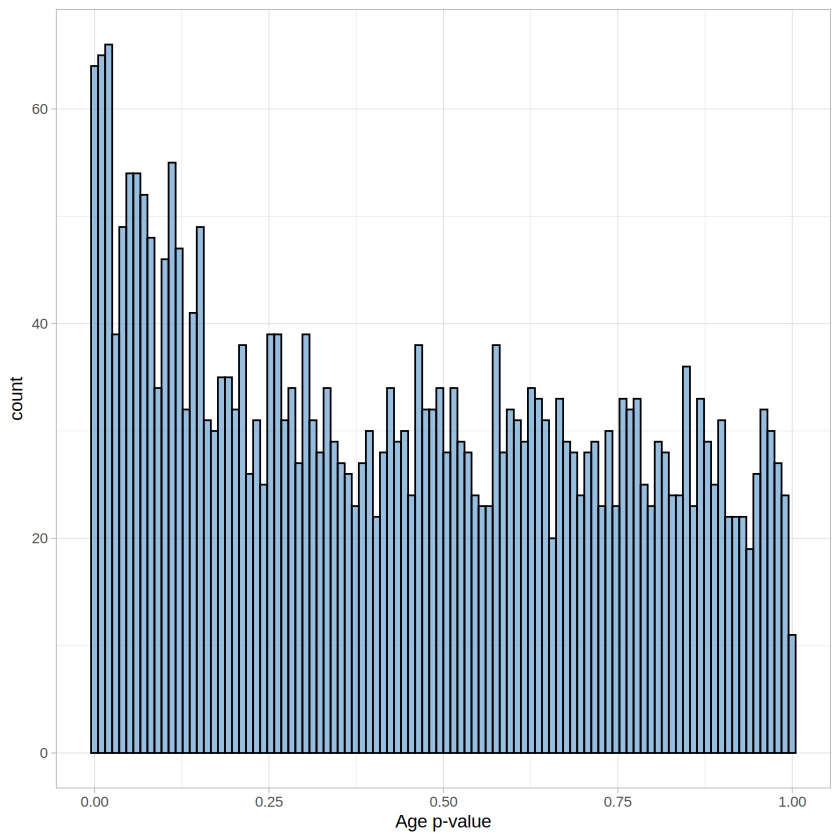

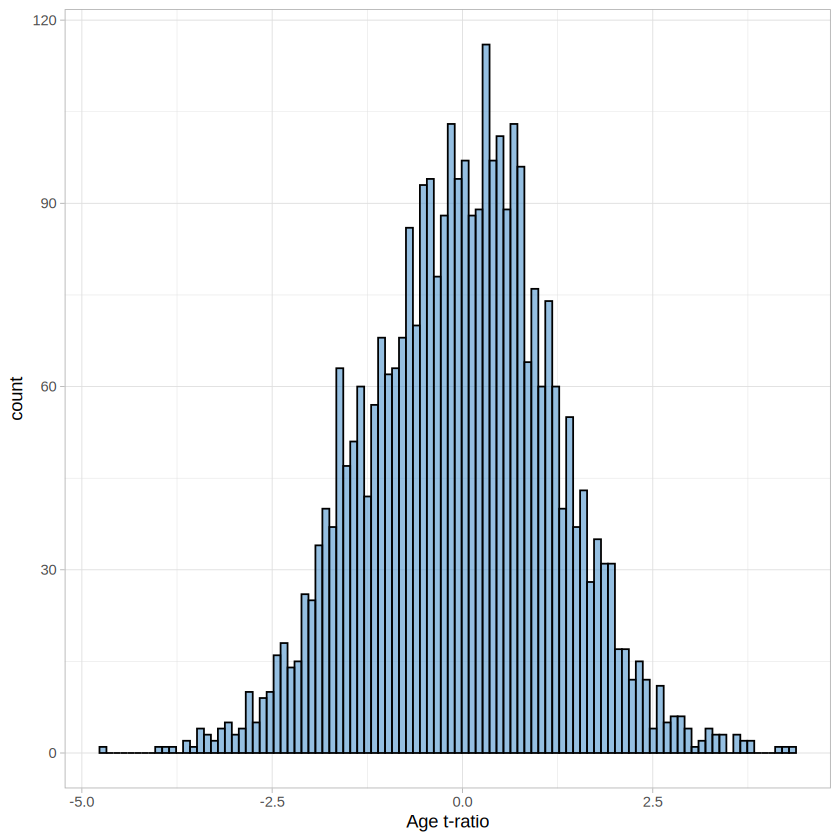

In [7]:
ggplot(linearModelAnalysis, aes(x=age_pval)) + geom_histogram(fill='steelblue3', col='black', bins=100, alpha=0.6) + xlab('Age p-value') + theme_light()
ggplot(linearModelAnalysis, aes(x=Age)) + geom_histogram(fill='steelblue3', col='black', bins=100, alpha=0.6) + xlab('Age t-ratio') + theme_light()

### Plot p-value and t-ratio distributions for Gender


Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_bin()`).”


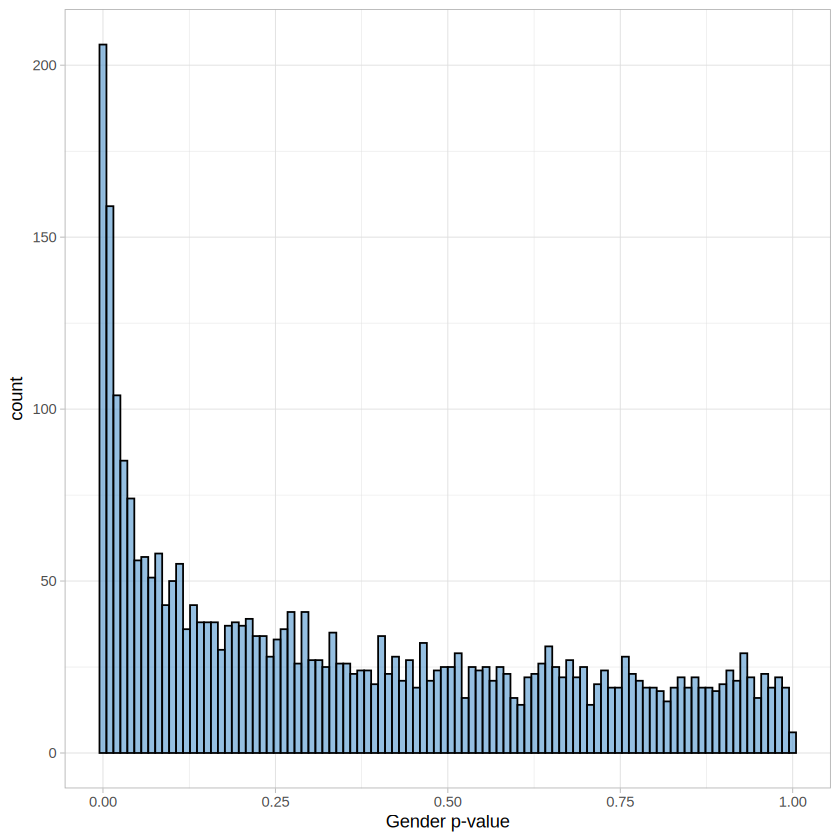

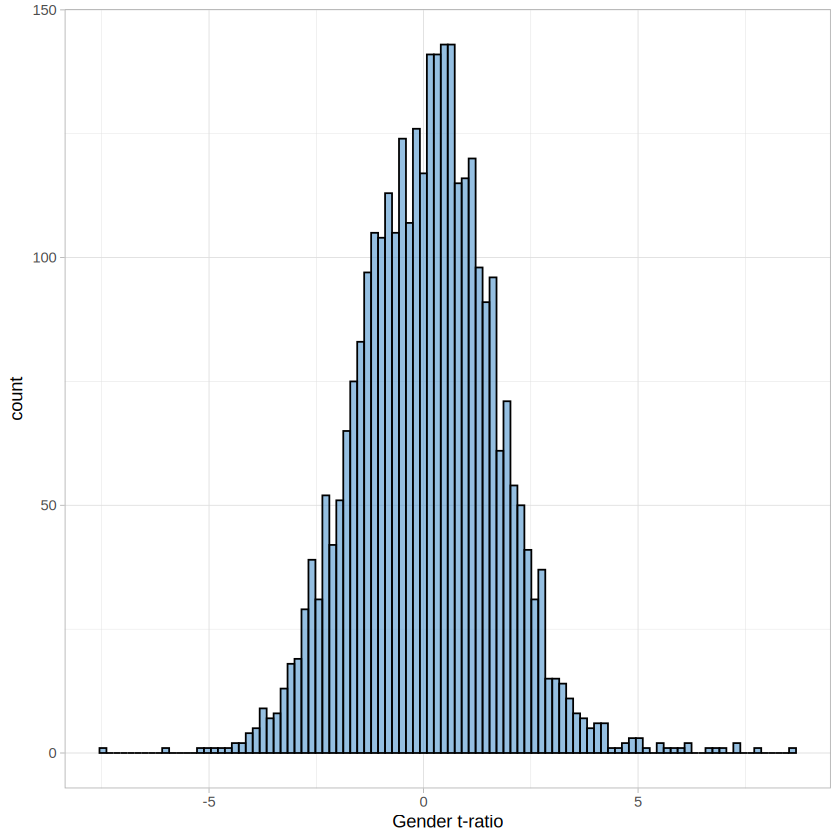

In [8]:
ggplot(linearModelAnalysis, aes(x=Gender_pval)) + geom_histogram(fill='steelblue3', col='black', bins=100, alpha=0.6) + xlab('Gender p-value') + theme_light()
ggplot(linearModelAnalysis, aes(x=Gender)) + geom_histogram(fill='steelblue3', col='black', bins=100, alpha=0.6) + xlab('Gender t-ratio') +theme_light()

## Multiple testing correction

In [9]:
bonferroniAge <- p.adjust(linearModelAnalysis$age_pval, method='bonferroni')
BHAge <- p.adjust(linearModelAnalysis$age_pval, method='BH')
BYAge <- p.adjust(linearModelAnalysis$age_pval, method='BY')

bonferroniGender <- p.adjust(linearModelAnalysis$Gender_pval, method='bonferroni')
BHGender <- p.adjust(linearModelAnalysis$Gender_pval, method='BH')
BYGender <- p.adjust(linearModelAnalysis$Gender_pval, method='BY')

### Volcano Plot - Gender

In [10]:
volcanoFrame <- data.frame(logFC=linearModelAnalysis$Gender_estimate, feature=colnames(lcMSDataset)[firstMetaboliteColIdx:ncol(lcMSDataset)], pvalue=linearModelAnalysis$Gender_pval,
                          qvalue = BYGender)
volcanoFrame$Significant <- 'No'
volcanoFrame$Significant[(volcanoFrame$qvalue < 0.05) & (volcanoFrame$logFC > 0)]  <- 'Higher in Male'
volcanoFrame$Significant[(volcanoFrame$qvalue < 0.05) & (volcanoFrame$logFC < 0)] <- 'Higher in Female'


VolcanoPlot <- ggplot(volcanoFrame, aes(x=logFC, y=-log10(pvalue))) + geom_point(aes(col=Significant)) + theme_minimal() +
  scale_colour_manual(values = c("No"="gray", "Higher in Male" = "firebrick1", "Higher in Female" = "steelblue3")) + xlab('logFC (age-adjusted)') + ylab('-log10(Pvalue)')

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


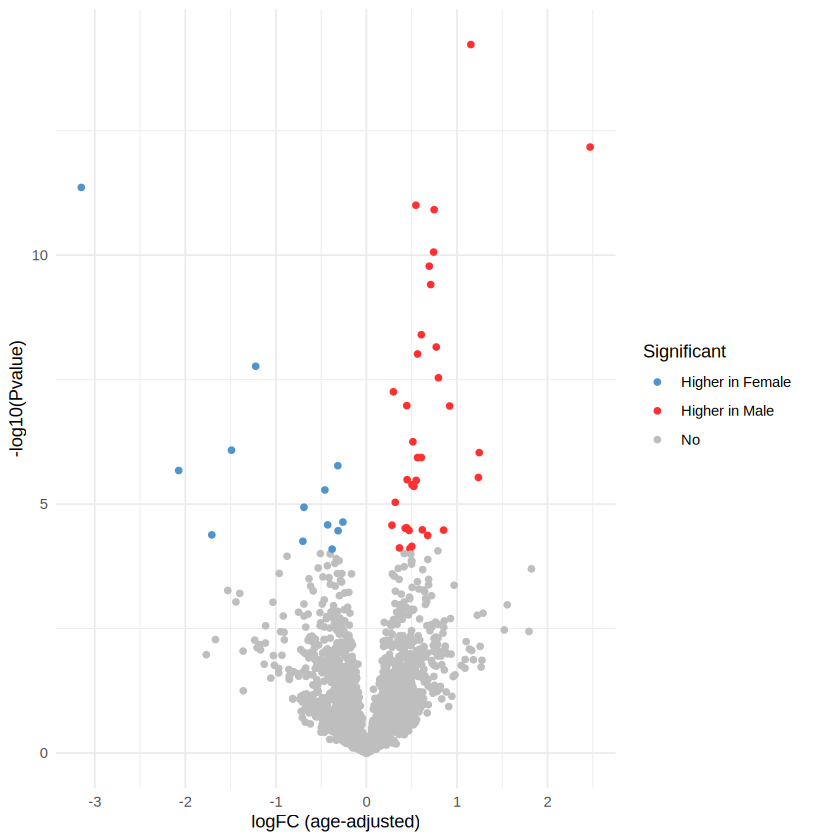

In [11]:
VolcanoPlot

### Volcano Plot - Age

For a continuous predictor, the x-axis shows the regression coefficient: the estimated change in `log(feature + 1)` per additional year of age, adjusted for Gender.

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


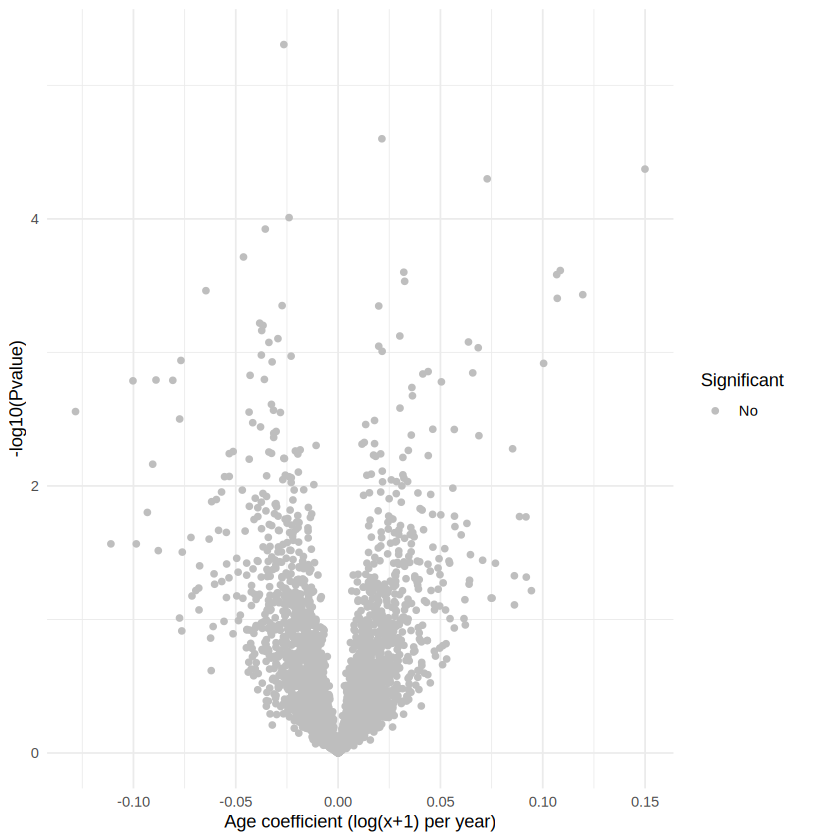

In [12]:
volcanoFrameAge <- data.frame(Age_coef=linearModelAnalysis$Age_estimate, feature=colnames(lcMSDataset)[firstMetaboliteColIdx:ncol(lcMSDataset)], pvalue=linearModelAnalysis$age_pval,
                              qvalue=BYAge)
volcanoFrameAge$Significant <- 'No'
volcanoFrameAge$Significant[(volcanoFrameAge$qvalue < 0.05) & (volcanoFrameAge$Age_coef > 0)] <- 'Increases with Age'
volcanoFrameAge$Significant[(volcanoFrameAge$qvalue < 0.05) & (volcanoFrameAge$Age_coef < 0)] <- 'Decreases with Age'

VolcanoPlotAge <- ggplot(volcanoFrameAge, aes(x=Age_coef, y=-log10(pvalue))) + geom_point(aes(col=Significant)) + theme_minimal() +
  scale_colour_manual(values = c('No'='gray', 'Increases with Age' = 'firebrick1', 'Decreases with Age' = 'steelblue3')) + xlab('Age coefficient (log(x+1) per year)') + ylab('-log10(Pvalue)')

VolcanoPlotAge

## Plot some of the significant features

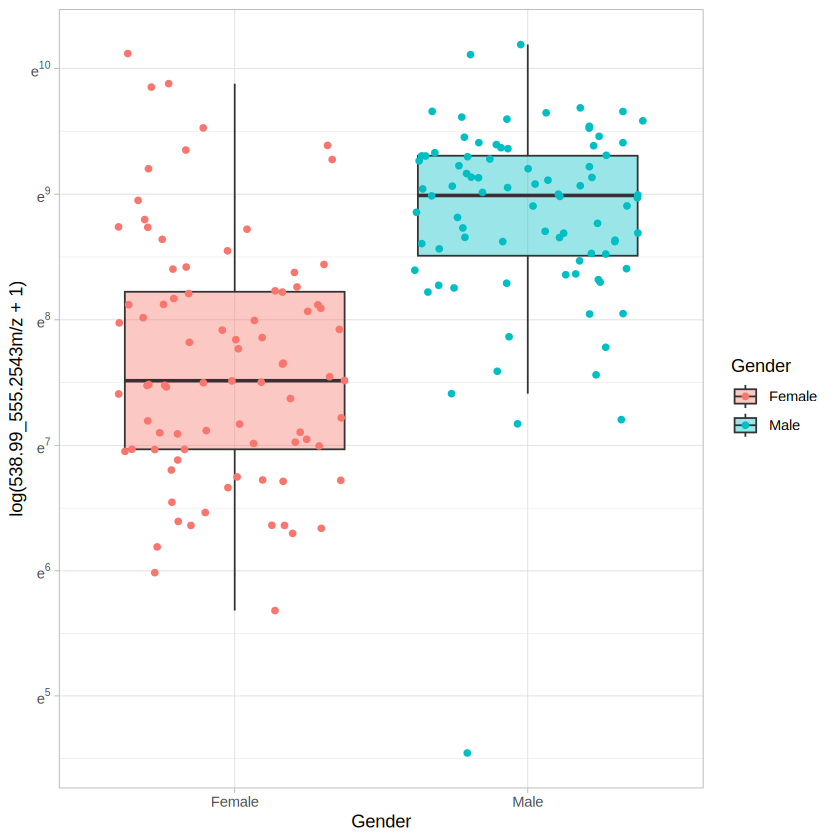

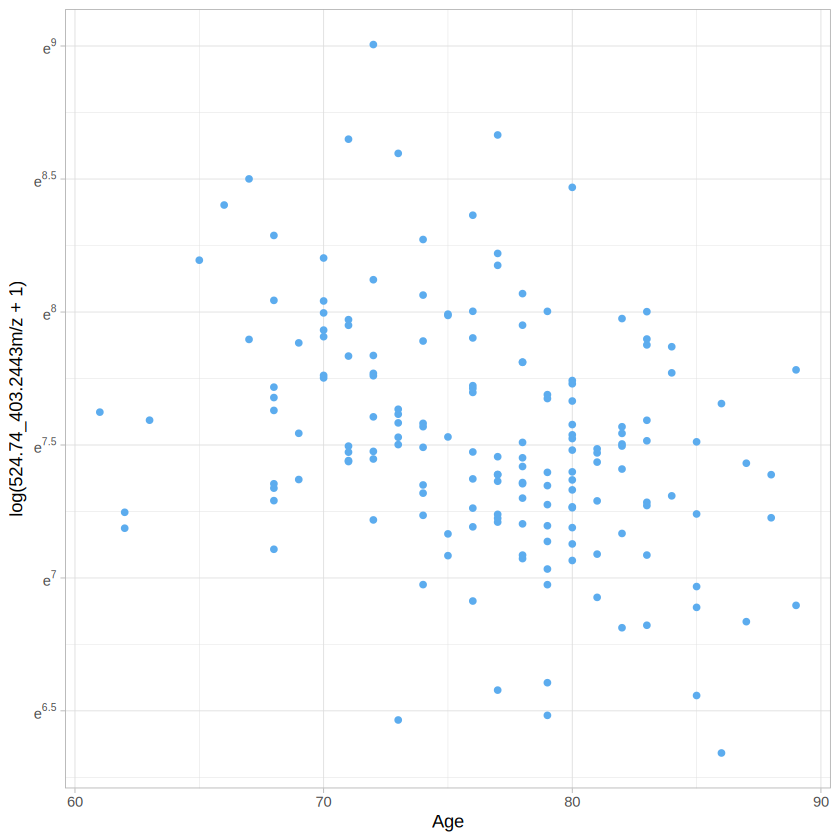

In [13]:
# Significant feature for Gender
feature <- linearModelAnalysis[which.min(BHGender), 'Feature']
ggplot(lcMSDataset, aes(x=Gender, y=get(feature))) + geom_boxplot(aes(fill=Gender), alpha=0.4, outlier.shape=NA) + geom_jitter(aes(col=Gender)) + xlab('Gender') + ylab(paste0('log(', feature, ' + 1)')) +  theme_light() + scale_y_continuous(trans = log1p_trans(), breaks = trans_breaks("log", function(x) exp(x)), labels = trans_format("log", math_format(e^.x)))

# Significant feature for Age
feature <- linearModelAnalysis[which.min(BHAge), 'Feature']
ggplot(lcMSDataset, aes(x=Age, y=get(feature))) + geom_point(col='steelblue2') + xlab('Age') + ylab(paste0('log(', feature, ' + 1)')) +  theme_light() + scale_y_continuous(trans = log1p_trans(), breaks = trans_breaks("log", function(x) exp(x)), labels = trans_format("log", math_format(e^.x)))

## Save the results

In [14]:
resultsDataFrame <- cbind(linearModelAnalysis, "FDR_BH_q-value_Gender" = BHGender, "FDR_BH_q-value_Age" = BHAge)
write.csv(resultsDataFrame, 'LinearRegressionAnalysis_RPOS.csv')